# **EV Battery Health Prediction, ETL & Training Model Notebook**

In this notebook we will extract the EV Battery Data from Kaggle.
We will clean up the data where nessesary.
Identifiy outliners and discuss if they need removing.
Visualise the data compareing feature using heatmaps and scatter plots.
Identify the best type of machine learning model to adapt.
Train the model and test it against the hypothese to see if the score can be improved.
Save the model to a file that we can provide to a streamlit tool where the predictions can be demonstrated.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "ev_battery_health.csv"
file_dictionary = "data_dictionary .csv"
# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "vinay24baghira/ev-battery-health-and-degradation-dataset",
  file_path
)

ddic = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "vinay24baghira/ev-battery-health-and-degradation-dataset",
  file_dictionary
)




c:\scripts\codeInst_projects\Project2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(df.dtypes)
df.describe(include='all')

battery_id                            str
observation_id                        str
chemistry                             str
manufacturer                          str
vehicle_model                         str
pack_capacity_kwh                 float64
manufacture_date                      str
observation_date                      str
battery_age_days                  float64
cycle_count                       float64
climate_zone                          str
avg_daily_distance_km             float64
avg_charging_power_kw             float64
fast_charge_ratio                 float64
avg_depth_of_discharge_pct        float64
avg_state_of_charge_pct           float64
charge_cycles_per_month           float64
total_energy_throughput_kwh       float64
avg_ambient_temp_c                float64
humidity_pct                      float64
altitude_m                        float64
internal_resistance_mohm          float64
voltage_avg_v                     float64
current_avg_a                     

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
count,50000,50000,46541,47539,46485,47698.000000,48090,47784,46998.000000,47731.000000,...,47872.000000,48131.000000,48400.000000,31169,47672,47354.000000,50000.000000,50000.000000,50000,50000
unique,2600,50000,4,8,8,NaN,1515,2106,NaN,NaN,...,NaN,NaN,NaN,2082,5,NaN,NaN,NaN,3,3
top,BATT_01842,OBS_033554,NMC,GigaWatt Labs,Van-E4,NaN,2026-01-24,2026-09-19,NaN,NaN,...,NaN,NaN,NaN,2025-09-23,BMS_v3.0,NaN,NaN,NaN,Low,Normal
freq,37,1,15984,6291,6185,NaN,122,96,NaN,NaN,...,NaN,NaN,NaN,54,9616,NaN,NaN,NaN,42735,46133
mean,NaN,NaN,NaN,NaN,NaN,72.650524,NaN,NaN,561.185455,570.535292,...,26.627565,7.065756,1.428574,NaN,NaN,0.015226,92.935170,1491.181860,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,14.487910,NaN,NaN,479.605930,599.964295,...,12.914975,7.117441,1.674035,NaN,NaN,0.122451,7.115968,1213.873203,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,40.000000,NaN,NaN,1.000000,1.000000,...,-10.903885,0.000000,0.000000,NaN,NaN,0.000000,55.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,62.500000,NaN,NaN,169.000000,137.000000,...,17.800000,1.950000,0.000000,NaN,NaN,0.000000,90.080000,600.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,72.600000,NaN,NaN,424.000000,371.000000,...,26.800000,4.800000,1.000000,NaN,NaN,0.000000,95.200000,1142.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,82.800000,NaN,NaN,846.000000,801.000000,...,35.600000,9.930000,2.000000,NaN,NaN,0.000000,98.050000,2322.000000,NaN,NaN


In [3]:
# 1 # Check for columns with missing data
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

if not missing_data.empty:
    print("Columns with missing data and their counts:")
    print(missing_data)
else:
    print("No missing data found in any column.")



Columns with missing data and their counts:
chemistry                          3459
manufacturer                       2461
vehicle_model                      3515
pack_capacity_kwh                  2302
manufacture_date                   1910
observation_date                   2216
battery_age_days                   3002
cycle_count                        2269
climate_zone                       2719
avg_daily_distance_km              2118
avg_charging_power_kw              2140
fast_charge_ratio                  3405
avg_depth_of_discharge_pct         2832
avg_state_of_charge_pct            3138
charge_cycles_per_month            2054
total_energy_throughput_kwh        3370
avg_ambient_temp_c                 3282
humidity_pct                       2737
altitude_m                         2322
internal_resistance_mohm           2104
voltage_avg_v                      2807
current_avg_a                      2487
charge_time_avg_min                2091
peak_temp_during_fast_charge_c     2

In [4]:
# 2 ##We can not have these rows in our data because there is not enough time/count data in the reading if all three are missing. 5 rows removed as we can't use those readings.  Forward thinking is time will be important and we can still substitute battery_age_days and cycle count to estimate when a reading happened
columns_to_check = ['observation_date', 'battery_age_days', 'cycle_count']

# Record starting shape
initial_shape = df.shape

# Drop rows where all three columns are null
df = df.dropna(subset=columns_to_check, how='all')

# Print changes
print(f"Original shape: {initial_shape}")
print(f"New shape: {df.shape}")
print(f"Removed rows: {initial_shape[0] - df.shape[0]}")

Original shape: (50000, 35)
New shape: (49995, 35)
Removed rows: 5


While the observation date and manufacture_date exist we can alway complete the missing battery age in days with a simple data operation on the data frame.

In [ ]:
## 3
df['observation_date'] = pd.to_datetime(df['observation_date'])
df['manufacture_date'] = pd.to_datetime(df['manufacture_date'])

# Calculate battery age in days from observation_date and manufacture_date
calculated_age = (df['observation_date'] - df['manufacture_date']).dt.days

# Impute only where 'battery_age_days' is currently missing
df['battery_age_days'] = df['battery_age_days'].fillna(calculated_age)

# Print missing count to verify imputation
print(f"Remaining missing 'battery_age_days': {df['battery_age_days'].isnull().sum()}")

Remaining missing 'battery_age_days': 233


In [ ]:
#4 
def get_non_null_value(battery_id, col_name):
    """
    Looks up a non-null value for a given battery_id and column name from df.
    """
    values = df[df['battery_id'] == battery_id][col_name].dropna()
    if not values.empty:
        return values.iloc[0]
    return np.nan

# Group the DataFrame by 'battery_id' to build an efficient lookup dictionary for each specified column
print("Populating gaps in the dataset for specified columns...")

# Specific columns to fill, these rows related to the battery pack and not the reading. So just for completelness.
columns_to_fill = ["chemistry", "manufacturer", "vehicle_model", "pack_capacity_kwh", "manufacture_date", "climate_zone"]

# Iterate and apply imputation using other rows of the same battery_id
for col in columns_to_fill:
    if col in df.columns:
        # Create a lookup mapping battery_id to its first non-null value for this column
        lookup_map = df.groupby('battery_id')[col].first()

        # Get indices where the column is null
        null_mask = df[col].isnull()

        # Map the battery_id of null rows to the lookup map
        imputed_values = df.loc[null_mask, 'battery_id'].map(lookup_map)

        # Fill the missing values
        df.loc[null_mask, col] = df.loc[null_mask, col].fillna(imputed_values)

# Verify new missing value counts for the selected columns
remaining_missing = df[columns_to_fill].isnull().sum()
print("\nRemaining missing data counts for targeted columns:")
print(remaining_missing)

Populating gaps in the dataset for specified columns...

Remaining missing data counts for targeted columns:
chemistry            0
manufacturer         0
vehicle_model        0
pack_capacity_kwh    0
manufacture_date     0
climate_zone         0
dtype: int64


In [9]:
# 5 # Define columns for each table, there are two tables if we think of the flat table as containing two objects, the battery and its readings.
battery_cols = ["battery_id", "chemistry", "manufacturer", "vehicle_model", "pack_capacity_kwh", "manufacture_date", "climate_zone"]
reading_cols = ["observation_id", "battery_id", "observation_date", "battery_age_days", "cycle_count", "avg_daily_distance_km", "avg_charging_power_kw", "fast_charge_ratio", "avg_depth_of_discharge_pct", "avg_state_of_charge_pct", "charge_cycles_per_month", "total_energy_throughput_kwh", "avg_ambient_temp_c", "humidity_pct", "altitude_m", "internal_resistance_mohm", "voltage_avg_v", "current_avg_a", "charge_time_avg_min", "peak_temp_during_fast_charge_c", "capacity_fade_pct", "service_count", "last_service_date", "bms_firmware_version", "recall_flag", "state_of_health_pct", "remaining_useful_life_cycles", "failure_risk_label", "degradation_category"]

# Create BatteryTable with unique battery_id entries
BatteryTable = df[battery_cols].drop_duplicates(subset=["battery_id"]).reset_index(drop=True)

# Create ReadingTable with unique observation_id entries
# Note: battery_id is included as a foreign key to maintain the relationship
ReadingTable = df[reading_cols].drop_duplicates(subset=["observation_id"]).reset_index(drop=True)

# Display table summaries and previews
print(f"BatteryTable shape: {BatteryTable.shape}")
print(f"ReadingTable shape: {ReadingTable.shape}")

print("\nBatteryTable preview:")
display(BatteryTable.head())

print("\nReadingTable preview:")
display(ReadingTable.head())

BatteryTable shape: (2600, 7)
ReadingTable shape: (49995, 29)

BatteryTable preview:


,battery_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,climate_zone
0,BATT_01748,LMO,StormCell,Crossover-X2,48.5,2022-11-23,cold
1,BATT_00491,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,cold
2,BATT_00011,LFP,IonFlux,Van-E4,73.1,2025-06-24,cold
3,BATT_00651,NMC,Amperion,Sport-E9,75.6,2022-08-13,cold
4,BATT_02054,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,hot_arid



ReadingTable preview:


,observation_id,battery_id,observation_date,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,avg_state_of_charge_pct,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,OBS_033554,BATT_01748,2024-10-16,693.0,991.0,120.3,NaN,0.345,65.7,66.6,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,OBS_009428,BATT_00491,2024-12-27,662.0,1535.0,93.4,74.7,0.569,74.2,51.2,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,OBS_000200,BATT_00011,2026-02-10,231.0,407.0,45.0,81.7,0.641,71.3,70.2,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,OBS_012448,BATT_00651,2022-09-15,33.0,29.0,42.4,76.0,0.596,33.1,79.2,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,OBS_039490,BATT_02054,2026-03-01,520.0,324.0,23.4,36.3,0.550,57.3,70.4,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


In [ ]:
display(ReadingTable.head())
display(BatteryTable.head())

In [ ]:
duplicate_count = ReadingTable.duplicated().sum()# No duplicate to sort out
duplicate_count

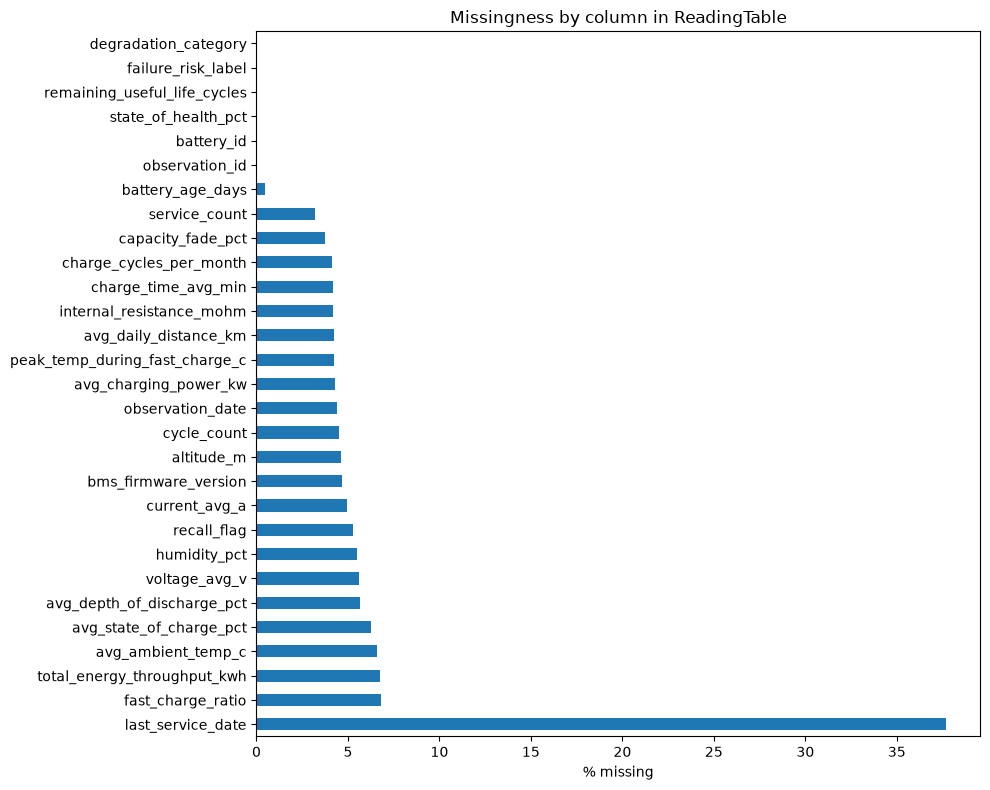

In [10]:
# 6 # Calculate the percentage of missing values for each column in ReadingTable
missing_pct = (ReadingTable.isnull().mean() * 100).sort_values(ascending=False)

# Plotting the missing percentage as a horizontal bar graph
plt.figure(figsize=(10, 8))
missing_pct.plot(kind='barh')
plt.xlabel('% missing')
plt.title('Missingness by column in ReadingTable')
plt.tight_layout()

# Save the figure to a PNG file
plt.savefig('missingness_by_column.png', dpi=300)
plt.show()

In [ ]:
ddic


In [11]:
#7 
def impute_battery_readings(df):
    """
    Fills missing values in ReadingTable using a moving average of past observations within each battery_id group.
    """
    # Create a working copy of the DataFrame
    imputed_df = df.copy()

    # Target features specified by the user
    target_features = [
        'capacity_fade_pct',
        'internal_resistance_mohm',
        'total_energy_throughput_kwh',
        'fast_charge_ratio',
        'cycle_count'
    ]

    # Step 1: Ensure date column is datetime format and sort chronologically within each battery_id
    imputed_df['observation_date'] = pd.to_datetime(imputed_df['observation_date'])
    imputed_df = imputed_df.sort_values(by=['battery_id', 'observation_date']).reset_index(drop=True)

    # Step 2: Define a function to perform rolling imputation on each battery group
    def process_group(group):
        for feature in target_features:
            if feature in group.columns:
                # Calculate moving average of past observations (closed on left to use only historical records)
                # We use a window size of 3 as a baseline (can adjust if required), min_periods=1
                rolling_avg = group[feature].shift(1).rolling(window=3, min_periods=1).mean()

                # Impute missing values using the moving average
                group[feature] = group[feature].fillna(rolling_avg)

                # Fallback ffill and bfill for initial boundary conditions or persistent NaNs
                group[feature] = group[feature].ffill().bfill()
        return group

    # Step 3: Apply the grouped operation strictly by battery_id while preserving battery_id column in the output DataFrame
    # We set group_keys=True so that the grouped keys are maintained, or we can restore the grouped index column.
    # Using group_keys=False and not using include_groups=False (keeping default or manually handling) ensures battery_id is retained.
    battery_ids = imputed_df['battery_id'].copy()

    imputed_df = imputed_df.groupby(
        'battery_id', group_keys=False
    ).apply(process_group)

    # Restore battery_id, aligned to the rows returned by apply
    imputed_df['battery_id'] = battery_ids.reindex(imputed_df.index)

    return imputed_df

# Run the imputation pipeline on ReadingTable
print("Missing counts before imputation:")
print(ReadingTable[['capacity_fade_pct', 'internal_resistance_mohm', 'total_energy_throughput_kwh', 'fast_charge_ratio', 'cycle_count']].isnull().sum())
ReadingTable = impute_battery_readings(ReadingTable)
print("\nMissing counts after imputation:")
print(ReadingTable[['capacity_fade_pct', 'internal_resistance_mohm', 'total_energy_throughput_kwh', 'fast_charge_ratio', 'cycle_count']].isnull().sum())

Missing counts before imputation:
capacity_fade_pct              1869
internal_resistance_mohm       2104
total_energy_throughput_kwh    3369
fast_charge_ratio              3405
cycle_count                    2264
dtype: int64

Missing counts after imputation:
capacity_fade_pct              0
internal_resistance_mohm       0
total_energy_throughput_kwh    0
fast_charge_ratio              0
cycle_count                    0
dtype: int64


In [12]:
#8 # Export the cleaned ReadingTable DataFrame to a CSV file check it in excel.
ReadingTable.to_csv('ReadingTable_cleaned.csv', index=False)
print("ReadingTable successfully saved to 'ReadingTable_cleaned.csv'")
print(f"ReadingTable shape: {ReadingTable.shape}")

# Export the cleaned ReadingTable DataFrame to a CSV file
BatteryTable.to_csv('BatteryTable_cleaned.csv', index=False)
print("BatteryTable successfully saved to 'BatteryTable_cleaned.csv'")
print(f"BatteryTable shape: {BatteryTable.shape}")

ReadingTable successfully saved to 'ReadingTable_cleaned.csv'
ReadingTable shape: (49995, 29)
BatteryTable successfully saved to 'BatteryTable_cleaned.csv'
BatteryTable shape: (2600, 7)


In [ ]:
BatteryTable.describe(include='all')


def distinct_counts(df, columns):
    rows = []
    for col in columns:
        rows.append({
            'column': col,
            'distinct_count': df[col].nunique(dropna=True),
            'including_nan': df[col].nunique(dropna=False)
        })
    return pd.DataFrame(rows)

cols = ['chemistry', 'manufacturer', 'vehicle_model',
        'pack_capacity_kwh', 'manufacture_date', 'climate_zone']

distinct_df = distinct_counts(BatteryTable, cols)
distinct_df


,column,distinct_count,including_nan
0,chemistry,4,4
1,manufacturer,8,8
2,vehicle_model,8,8
3,pack_capacity_kwh,588,588
4,manufacture_date,1515,1515
5,climate_zone,5,5


In [16]:

cols = ['capacity_fade_pct', 'internal_resistance_mohm',  'total_energy_throughput_kwh',  'fast_charge_ratio', 'state_of_health_pct']
ReadingTable[cols].describe()



,capacity_fade_pct,internal_resistance_mohm,total_energy_throughput_kwh,fast_charge_ratio,state_of_health_pct
count,49995.000000,49995.000000,49995.000000,49995.000000,49995.000000
mean,7.032573,49.112511,38088.950077,0.294608,92.935225
std,7.101504,21.241235,42013.763296,0.172429,7.116174
min,0.000000,7.676580,36.400000,0.000000,55.000000
25%,1.930000,34.790000,8706.650000,0.162000,90.080000
50%,4.773333,42.990000,23790.500000,0.272000,95.200000
75%,9.890000,56.840000,52741.150000,0.407000,98.050000
max,45.000000,307.090497,402419.900000,0.939000,100.000000


These statistic about the battery health

In [ ]:
# 9 #create heat maps for initial corralation detection to the target State of Health (SoH)
## Given in the dataset that this is the target.    But there maybe other targets linked to it.
def plot_chemistry_heatmaps(df, target_col='state_of_health_pct'):
    chemistries = ['LMO', 'LFP', 'NMC', 'NCA']
    features = [
        'capacity_fade_pct',
        'internal_resistance_mohm',
        'total_energy_throughput_kwh',
        'fast_charge_ratio',
        target_col
    ]

    # Create a grid of 1 row x 4 columns for comparison
    fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)

    for i, chem in enumerate(chemistries):
        # Filter dataset by chemistry type
        chem_df = df[df['chemistry'] == chem][features]
        corr_matrix = chem_df.corr()

        # Plot individual heatmap
        sns.heatmap(
            corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[i],
            cbar=(i == 3), # Show colorbar only on the last plot
            vmin=-1,
            vmax=1
        )
        axes[i].set_title(f'Chemistry: {chem}')

    plt.tight_layout()
    plt.show()

In [ ]:
# 10. Merge ReadingTable with BatteryTable using battery_id
merged_df = pd.merge(
    ReadingTable,
    BatteryTable[['battery_id', 'chemistry', 'manufacturer']],  # Pull only the chemistry and manufacturer columns needed
    on='battery_id',
    how='inner',
)

In [ ]:
numeric_cols = merged_df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(14, 11))
sns.heatmap(merged_df[numeric_cols].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix — numeric features')
plt.tight_layout()
plt.show()

In [ ]:
##11 added statistic on the boundary of other SoH levels.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Configure visual settings
plt.figure(figsize=(18, 5))

# 1. State of Health vs Average Remaining Useful Life Cycles
# Since SoH is continuous, we group by integer SoH levels to find the average RUL
merged_df['soh_int'] = merged_df['state_of_health_pct'].round().astype(int)
avg_rul_by_soh = merged_df.groupby('soh_int')['remaining_useful_life_cycles'].mean().reset_index()

plt.subplot(1, 3, 1)
sns.lineplot(data=avg_rul_by_soh, x='soh_int', y='remaining_useful_life_cycles', marker='o', color='blue', linewidth=2.5)
plt.title('Average Remaining RUL Cycles by State of Health', fontsize=12)
plt.xlabel('State of Health (%)')
plt.ylabel('Average Remaining Useful Life (Cycles)')
plt.grid(True, linestyle='--', alpha=0.6)

# 2. State of Health vs Failure Risk Label
# Boxplot is highly suitable for continuous vs categorical to show distributions clearly
plt.subplot(1, 3, 2)
risk_order = ['Low', 'Medium', 'High']
sns.boxplot(data=merged_df, x='failure_risk_label', y='state_of_health_pct', order=risk_order, palette='Oranges', hue='failure_risk_label', legend=False)
plt.title('State of Health by Failure Risk Label', fontsize=12)
plt.xlabel('Failure Risk Label')
plt.ylabel('State of Health (%)')
plt.grid(True, linestyle='--', alpha=0.6)

# 3. State of Health vs Degradation Category
plt.subplot(1, 3, 3)
degradation_order = ['Normal', 'Accelerated', 'Critical']
sns.boxplot(data=merged_df, x='degradation_category', y='state_of_health_pct', order=degradation_order, palette='Reds', hue='degradation_category', legend=False)
plt.title('State of Health by Degradation Category', fontsize=12)
plt.xlabel('Degradation Category')
plt.ylabel('State of Health (%)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
##12
import pandas as pd

# Group by failure_risk_label and calculate quartiles for state_of_health_pct
risk_quartiles = merged_df.groupby('failure_risk_label')['state_of_health_pct'].quantile([0.25, 0.50, 0.75]).unstack()
risk_quartiles.columns = ['Lower Quartile (25%)', 'Median (50%)', 'Upper Quartile (75%)']
risk_quartiles = risk_quartiles.reindex(['Low', 'Medium', 'High'])

print("--- State of Health Boundaries by Failure Risk Label ---")
display(risk_quartiles)

# Group by degradation_category and calculate quartiles for state_of_health_pct
degradation_quartiles = merged_df.groupby('degradation_category')['state_of_health_pct'].quantile([0.25, 0.50, 0.75]).unstack()
degradation_quartiles.columns = ['Lower Quartile (25%)', 'Median (50%)', 'Upper Quartile (75%)']
degradation_quartiles = degradation_quartiles.reindex(['Normal', 'Accelerated', 'Critical'])

print("\n--- State of Health Boundaries by Degradation Category ---")
display(degradation_quartiles)

In [ ]:
##13
def plot_global_heatmap(df, target_col='state_of_health_pct'):
    features = [
        'capacity_fade_pct',
        'internal_resistance_mohm',
        'total_energy_throughput_kwh',
        'fast_charge_ratio',
        'avg_charging_power_kw',
        target_col,
    ]

    plt.figure(figsize=(8, 6))

    # Calculate correlation matrix for numerical features
    corr = df[features].corr()

    # Draw single heatmap
    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        linewidths=0.5,
    )

    plt.title('Global Correlation Matrix (All Battery Readings)', fontsize=14)
    plt.tight_layout()
    plt.show()


# Execute global heatmap
plot_global_heatmap(merged_df)

In [ ]:
##14
def plot_chemistry_heatmaps(df, target_col='state_of_health_pct'):
    chemistries = ['LMO', 'LFP', 'NMC', 'NCA']
    features = [
        'capacity_fade_pct',
        'internal_resistance_mohm',
        'total_energy_throughput_kwh',
        'fast_charge_ratio',
        target_col,
    ]

    # Create a 1-row by 4-column figure grid
    fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)

    for i, chem in enumerate(chemistries):
        # Filter merged data for the current chemistry
        chem_data = df[df['chemistry'] == chem][features]

        # Handle edge case: Ensure group is not empty before computing correlation
        if len(chem_data) > 0:
            corr = chem_data.corr()

            sns.heatmap(
                corr,
                annot=True,
                fmt='.2f',
                cmap='coolwarm',
                ax=axes[i],
                cbar=(
                    i == 3
                ),  # Display colorbar only on the far right chart for cleanliness
                vmin=-1,
                vmax=1,
            )
            axes[i].set_title(f'Chemistry: {chem}', fontsize=12)
        else:
            axes[i].set_title(f'{chem} (No Data)', fontsize=12)

    plt.suptitle(
        'Feature Correlation by Cell Chemistry', fontsize=16, y=1.05
    )
    plt.tight_layout()
    plt.show()


# Execute chemistry subplots
plot_chemistry_heatmaps(merged_df)

In [ ]:
##14
def analyze_feature_correlations(
    df: pd.DataFrame, target_col: str = 'state_of_health_pct'
):
    # Select only numeric columns
    numeric_df = df.select_dtypes(include=['number'])

    # Compute correlation specifically with the target variable
    target_corr = numeric_df.corr()[target_col].drop(target_col)

    # Sort correlations from strongest to weakest
    sorted_corr = target_corr.abs().sort_values(ascending=False)

    print("--- Correlation with State of Health ---")
    print(target_corr.loc[sorted_corr.index])

    # Filter out features with near-zero linear correlation (|r| < 0.05)
    weak_features = sorted_corr[sorted_corr < 0.05].index.tolist()

    print(
        f"\nCandidate features for non-linear testing or removal ({len(weak_features)}):"
    )
    print(weak_features)

    return weak_features


analyze_feature_correlations(merged_df)

we don't know remaining_useful_life_cycles on a battery because that is calculated from the energy state_of_health_pct value.

so we only have 4 top for the Correlation Matrix in relation to state of health they are.

'internal_resistance_mohm',
'cycle_count',
'total_energy_throughput_kwh',
'battery_age_days',


In [ ]:
##15
import matplotlib.pyplot as plt
import seaborn as sns

# Define our refined core physical feature set (excluding target leakage)
core_features = [
    'internal_resistance_mohm',
    'cycle_count',
    'total_energy_throughput_kwh',
    'battery_age_days',
    'state_of_health_pct',  # Target feature
]


def plot_vertical_chemistry_heatmaps(df, features):
    chemistries = ['LMO', 'LFP', 'NMC', 'NCA']

    # Set up 4 vertical subplots (4 rows, 1 column)
    # TODO: Fill in subplots(nrows, ncols, figsize=(width, height))
    fig, axes = plt.subplots(4, 1, figsize=(8, 20))

    for i, chem in enumerate(chemistries):
        # Filter for current chemistry group
        chem_df = df[df['chemistry'] == chem][features]

        if len(chem_df) > 0:
            corr_matrix = chem_df.corr()

            # Plot heatmap on the corresponding vertical axis (axes[i])
            sns.heatmap(
                corr_matrix,
                annot=True,
                fmt='.2f',
                cmap='coolwarm',
                ax=axes[i],
                vmin=-1,
                vmax=1,
                cbar=(
                    i == 0
                ),  # Display colorbar on top plot only to save space
            )
            axes[i].set_title(f'Battery Chemistry: {chem}', fontsize=12)

    plt.tight_layout()
    plt.show()


# Run heatmap display on your merged dataset
plot_vertical_chemistry_heatmaps(merged_df, core_features)

In [ ]:
# 16
# Create 1 row with 4 subplots side-by-side
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# Plot 1: State of Health
merged_df['state_of_health_pct'].hist(bins=100, ax=axes[0])
axes[0].set_title('State of Health (%)')
axes[0].set_xlabel('current capacity as %')
axes[0].set_ylabel('% frequency')

# Plot 2: Failure Risk Label
merged_df['failure_risk_label'].value_counts().plot(kind='bar', edgecolor='black', ax=axes[1])
axes[1].set_title('Failure Risk Label (imbalanced)')
axes[1].set_ylabel('Group Category frequency')

# Plot 3: Degradation Category
merged_df['degradation_category'].value_counts().plot(kind='bar', edgecolor='black', ax=axes[2])
axes[2].set_title('Degradation Category')
axes[2].set_ylabel('Group Category frequency')

# Plot 4: Cycle Count Distribution (1 to 5100)
merged_df['cycle_count'].hist(
    bins=800,
    range=(1, 5100),
    ax=axes[3],
)
axes[3].set_title('Cycle Count Distribution (1-5100)')
axes[3].set_xlabel('Cycle Count')
axes[3].set_ylabel('Group reading frequency')

plt.tight_layout()
plt.show()

In [ ]:
#17
import matplotlib.pyplot as plt
import seaborn as sns

# Features specified by the user
features_to_plot = [
    'voltage_avg_v', 'avg_ambient_temp_c', 'peak_temp_during_fast_charge_c',
    'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct', 'current_avg_a',
    'recall_flag', 'fast_charge_ratio', 'avg_charging_power_kw',
    'altitude_m', 'charge_time_avg_min', 'humidity_pct'
]

# Create a 4x3 grid of subplots
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    if feature in merged_df.columns:
        sns.boxplot(data=merged_df, y=feature, ax=axes[i], color='skyblue')
        axes[i].set_title(f'Box Plot of {feature}', fontsize=12)
        axes[i].set_ylabel('')
    else:
        axes[i].set_title(f'{feature} (Not Found)', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
##18
## first Machine learning measure 
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Select continuous numerical features to test for clusters
features_for_clustering = [
    'internal_resistance_mohm',
    'total_energy_throughput_kwh',
    'cycle_count'
]
##  'avg_charging_power_kw',
##  'fast_charge_ratio'

# Extract feature matrix X and category labels
X_raw = merged_df[features_for_clustering].dropna()
labels = merged_df.loc[X_raw.index, 'degradation_category']

# 2. Scale features so distance calculations are accurate
scaler = StandardScaler()
# TODO: Fit and transform X_raw using scaler.fit_transform()
X_scaled = scaler.fit_transform(X_raw)

# 3. Calculate Silhouette Score for existing degradation_category labels
score = silhouette_score(X_scaled, labels)
print(f'Silhouette Score for degradation_category: {score:.3f}')

In [ ]:
##19
import matplotlib.pyplot as plt
import seaborn as sns


def plot_degradation_clusters(df):
    # Adjust width to 20 so 5 horizontal plots have plenty of room
    fig, axes = plt.subplots(1, 6, figsize=(20, 5))

    category_colors = {
        'Normal': 'green',
        'Accelerated': 'orange',
        'Critical': 'red',
    }

    # Define plot configuration as a list of tuples: (x_column, title)
    plot_configs = [
        ('battery_age_days', 'Battery Age (days) vs SoH'),
        ('internal_resistance_mohm', 'Internal Resistance vs SoH'),
        ('avg_charging_power_kw', 'Avg Charging Power vs SoH'),
        ('fast_charge_ratio', 'Fast Charge Ratio vs SoH'),
        ('total_energy_throughput_kwh', 'Throughput vs SoH'),
        ('cycle_count', 'Cycles vs SoH')
    ]

    # Loop through each plot configuration
    for i, (x_col, title) in enumerate(plot_configs):
        sns.scatterplot(
            data=df,
            x=x_col,
            y='state_of_health_pct',
            hue='degradation_category',
            palette=category_colors,
            alpha=0.6,
            legend=(
                i == 0
            ),  # Keep legend ONLY on first plot temporarily to extract handles
            ax=axes[i],
        )
        axes[i].set_title(title, fontsize=10)

    # Extract legend handles & labels from the first plot, then remove its local legend box
    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].get_legend().remove()

    # Create a single unified legend on the far left of the entire figure
    fig.legend(
        handles,
        labels,
        loc='center left',
        bbox_to_anchor=(0.01, 0.5),  # Positioned at far left edge
        title='Degradation Category',
        frameon=True,
    )

    # Leave whitespace on the left (0.10) for the legend box
    plt.subplots_adjust(left=0.10, wspace=0.3)
    plt.show()


# Run the updated function
plot_degradation_clusters(merged_df)

We know now the intention of the labels Accelerated, Critical and Normal are just mapped to the 70% 80% and above state of health. Other points shown as a different colour in the wrong cluster are likely mis-classifications. You can clearly see sharp horizontal boundary lines cut right at 80% and 70% on the y-axis (state_of_health_pct): Normal:  SoH≥80%  (Green) Accelerated:  70%≤SoH<80%  (Orange) Critical:  SoH<70%  (Red)

In [ ]:
## 20
import matplotlib.pyplot as plt
import seaborn as sns


def plot_clean_feature_pairgrid(df):
    plot_features = [
        'battery_age_days',
        'internal_resistance_mohm',
        'cycle_count',
        'total_energy_throughput_kwh',
        'degradation_category',
        'chemistry',
    ]
    clean_df = df[plot_features].dropna()

    color_map = {'Normal': 'green', 'Accelerated': 'orange', 'Critical': 'red'}

    # 1. Initialize PairGrid with hue (color)
    g = sns.PairGrid(
        clean_df,
        vars=[
            'battery_age_days',
            'internal_resistance_mohm',
            'cycle_count',
            'total_energy_throughput_kwh',
        ],
        hue='degradation_category',
        palette=color_map,
    )

    # 2. Map KDE curves on the diagonal plots
    g.map_diag(sns.kdeplot, fill=True, alpha=0.3)

    # 3. Map Scatter Plots on off-diagonal plots with custom markers for style
    # (Note: style='chemistry' can be passed directly inside map_offdiag!)
    g.map_offdiag(
        sns.scatterplot, style=clean_df['chemistry'], alpha=0.6, s=30
    )

    g.add_legend()
    g.fig.suptitle(
        '4-Feature PairGrid (Color: Degradation, Shape: Chemistry)',
        y=1.02,
        fontsize=14,
    )
    plt.show()


# Run updated function
plot_clean_feature_pairgrid(merged_df)

In [ ]:
## 21
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_feature_pairgrid(df: pd.DataFrame):
    # 1. Feature Selection
    plot_features = [
        'battery_age_days',
        'fast_charge_ratio',
        'avg_charging_power_kw',
        'internal_resistance_mohm',
        'cycle_count',
        'total_energy_throughput_kwh',
    ]
    all_cols = plot_features + ['state_of_health_pct']
    plot_df = df[all_cols].dropna().copy()

    # 2. Clip SoH to 60-100 range
    plot_df['soh_clipped'] = plot_df['state_of_health_pct'].clip(
        lower=60, upper=100
    )

    # 3. Initialize PairGrid WITHOUT hue (we apply hue manually to off-diagonals)
    g = sns.PairGrid(plot_df, vars=plot_features)

    # 4. Map Histograms on the Diagonal
    g.map_diag(sns.histplot, color='gray', kde=True, alpha=0.4)

    # 5. Map Scatter Plots with Continuous Hue & Marker Styles
    # We iterate over the grid axes to apply continuous color shading safely
    for i, val_y in enumerate(plot_features):
        for j, val_x in enumerate(plot_features):
            if i != j:  # Off-diagonal plots only
                sns.scatterplot(
                    data=plot_df,
                    x=val_x,
                    y=val_y,
                    hue='soh_clipped',
                    hue_norm=(60, 100),
                    palette='viridis',
                    alpha=0.7,
                    s=30,
                    ax=g.axes[i, j],
                    legend=False,  # Suppress repeat legends on subplots
                )

    # 6. Customize Layout & Add Unified Colorbar
    g.fig.subplots_adjust(top=0.93, right=0.88)

    # Add continuous color legend
    sm = plt.cm.ScalarMappable(
        cmap='viridis', norm=plt.Normalize(vmin=60, vmax=100)
    )
    sm.set_array([])
    cbar_ax = g.fig.add_axes([0.91, 0.3, 0.02, 0.4])
    cbar = g.fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('State of Health (%)', fontsize=12)

    # Title
    g.fig.suptitle(
        'Battery Features PairGrid (Color: SoH 60-100)',
        fontsize=16,
    )
    plt.show()


# Run function
plot_feature_pairgrid(merged_df)

In [ ]:
## 22
import matplotlib.pyplot as plt
import seaborn as sns

# Define the custom chemistry color palette requested by the user
chemistry_colors = {
    'LMO': '#1f77b4',   # Blue
    'LFP': '#2ca02c',   # Green
    'NMC': '#9467bd',   # Purple
    'NCA': '#d62728'    # Red
}

# Create a side-by-side plot layout (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Chart 1: State of Health vs Cycle Count
sns.scatterplot(
    data=merged_df,
    x='cycle_count',
    y='state_of_health_pct',
    hue='chemistry',
    palette=chemistry_colors,
    alpha=0.6,
    s=15,
    ax=axes[0]
)
axes[0].set_title('State of Health vs Cycle Count by Chemistry', fontsize=12)
axes[0].set_xlabel('Cycle Count')
axes[0].set_ylabel('State of Health (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Chart 2: State of Health vs Internal Resistance
sns.scatterplot(
    data=merged_df,
    x='internal_resistance_mohm',
    y='state_of_health_pct',
    hue='chemistry',
    palette=chemistry_colors,
    alpha=0.6,
    s=15,
    ax=axes[1]
)
axes[1].set_title('State of Health vs Internal Resistance by Chemistry', fontsize=12)
axes[1].set_xlabel('Internal Resistance (mΩ)')
axes[1].set_ylabel('State of Health (%)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Battery Degradation Analysis by Chemistry Type', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
## 23
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse the custom chemistry color palette
chemistry_colors = {
    'LMO': '#1f77b4',
    'LFP': '#2ca02c',
    'NMC': '#9467bd',
    'NCA': '#d62728'
}

# Create a 1 row by 2 columns layout for the three new charts
fig, axes = plt.subplots(1, 2, figsize=(22, 6), sharey=True)

# Chart 3: State of Health vs Battery Age (Days)
sns.scatterplot(
    data=merged_df,
    x='battery_age_days',
    y='state_of_health_pct',
    hue='chemistry',
    palette=chemistry_colors,
    alpha=0.6,
    s=15,
    ax=axes[0]
)
axes[0].set_title('State of Health vs Battery Age by Chemistry', fontsize=12)
axes[0].set_xlabel('Battery Age (days)')
axes[0].set_ylabel('State of Health (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)


# Chart 4: State of Health vs Total Energy Throughput
sns.scatterplot(
    data=merged_df,
    x='total_energy_throughput_kwh',
    y='state_of_health_pct',
    hue='chemistry',
    palette=chemistry_colors,
    alpha=0.6,
    s=15,
    ax=axes[1]
)
axes[1].set_title('State of Health vs Throughput by Chemistry', fontsize=12)
axes[1].set_xlabel('Total Energy Throughput (kWh)')
axes[1].set_ylabel('State of Health (%)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Extended Battery Degradation Analysis by Chemistry Type', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

internal_resistance_mohm (Universal Signal): Regardless of whether a cell is LFP, NMC, NCA, or LMO, high internal resistance is a universal physical symptom of severe degradation (lithium loss, electrolyte drying, and passive film growth).

cycle_count, battery_age_days, and total_energy_throughput_kwh (Chemistry-Dependent): An LFP (Lithium Iron Phosphate) battery can handle thousands of cycles with minimal loss, whereas an LMO or NCA battery wears out much faster over the same cycle count. This was visible in your previous chemistry plot, where green LFP points stayed lower while other chemistries climbed higher. based on that we should learn which feature and the feature with interactions (chemistry) we should be able to build a solid model now.
My hypothesis is now updated to suggest that the internal_resistance_mohm matrics should have one of the highest overall importance scores. Then the usage metrics (cycle_count, total_energy_throughput_kwh, battery_age_days) should share significant weight alongside the one-hot encoded chemistry columns. A good model for prediction would best be fitted RandomForestRegressor. I have chosen this because I want the model to use a Tree-based algorithms like Random Forest and XGBoost. Apparently they are popular for battery modeling because they learn these exact interactions we have observed automatically without requiring manual math formulas. A single decision tree inside the Random Forest naturally creates branches that mirror your logic: That Is internal_resistance > 120 mΩ? (for example) yes or no? Then Is chemistry == 'LFP' [ Evaluate cycles with SLOW decay ] or [with FAST decay]

Then as we teach the model how a battery works it should be able to perform well at predictions.

In [ ]:
## 24
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Define feature columns and target variable
features = [
    'internal_resistance_mohm',
    'cycle_count',
    'total_energy_throughput_kwh',
    'battery_age_days',
    'chemistry',
]
target = 'state_of_health_pct'

# Extract clean rows without missing values
df_model = merged_df[features + [target]].dropna().copy()

# 2. One-Hot Encode categorical features ('chemistry')
X = pd.get_dummies(df_model[features], columns=['chemistry'], drop_first=True)
y = df_model[target]

# 3. Split into 80% Training set and 20% Testing set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Initialize and train a Random Forest Regressor baseline
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 5. Generate predictions on unseen test data
y_pred = rf_model.predict(X_test)

# 6. Evaluate Performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('--- Baseline Random Forest Performance ---')
print(f'Mean Absolute Error (MAE): {mae:.2f}%')
print(f'R² Score: {r2:.4f}')

In [ ]:
# 25

import pandas as pd

# Assume 'rf_model' is your fitted RandomForestRegressor
# and 'X_train' contains your feature column names

# 1. Extract feature importances from the fitted model
importances = rf_model.feature_importances_

# TODO: Create a pandas DataFrame linking feature names to their importance scores
# Hint: Use X_train.columns as the index or column
feature_imp_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# TODO: Print or plot the sorted feature importances
print(feature_imp_df)

In [ ]:
## 26
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# 1. Prepare clean data
df_prob = merged_df[
    ['internal_resistance_mohm', 'state_of_health_pct']
].dropna().copy()

# 2. Define two binary targets based on our known thresholds
df_prob['is_below_80'] = (df_prob['state_of_health_pct'] < 80.0).astype(int)
df_prob['is_below_70'] = (df_prob['state_of_health_pct'] < 70.0).astype(int)

X = df_prob[['internal_resistance_mohm']]

# 3. Fit Model 1 (80% Threshold)
model_80 = LogisticRegression()
model_80.fit(X, df_prob['is_below_80'])

# 4. Fit Model 2 (70% Threshold)
model_70 = LogisticRegression()
model_70.fit(X, df_prob['is_below_70'])

# 5. Generate smooth continuous x-values for plotting
x_range = np.linspace(
    X['internal_resistance_mohm'].min(),
    X['internal_resistance_mohm'].max(),
    300,
).reshape(-1, 1)

# Calculate probabilities
prob_80 = model_80.predict_proba(x_range)[:, 1]

# TODO: Complete the probability calculation for model_70 (70% threshold)
# Hint: Use model_70.predict_proba(x_range)[:, 1]
prob_70 = model_70.predict_proba(x_range)[:, 1]

# 6. Plot Dual Sigmoid Curves
plt.figure(figsize=(11, 6))

# Plot the 80% transition curve (Orange)
plt.plot(
    x_range,
    prob_80,
    color='orange',
    linewidth=3,
    label='P(SoH < 80%): Transition to Accelerated',
)

# Plot the 70% transition curve (Red)
plt.plot(
    x_range,
    prob_70,
    color='red',
    linewidth=3,
    label='P(SoH < 70%): Transition to Critical',
)

# Reference Lines
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.7, label='50% Risk Cutoff')

# Plot Aesthetics
plt.title(
    'Multi-Stage Failure Risk vs Internal Resistance', fontsize=14, pad=12
)
plt.xlabel('Internal Resistance (mΩ)', fontsize=12)
plt.ylabel('Failure Probability P(Y)', fontsize=12)
plt.legend(loc='center right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
## 27

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_chemistry_risk_matrix(df):
    # 1. Clean missing data
    clean_df = df[['chemistry', 'degradation_category']].dropna().copy()

    # 2. Build cross-tabulation table
    # TODO: Add normalize='index' inside pd.crosstab so each row calculates percentages summing to 1.0
    risk_matrix = (
        pd.crosstab(
            clean_df['chemistry'],
            clean_df['degradation_category'],
            normalize='index',  # Calculates proportion per chemistry row
        )
        * 100
    )  # Multiply by 100 to convert to percentages

    # Ensure columns appear in natural health order
    desired_order = ['Normal', 'Accelerated', 'Critical']
    ordered_cols = [c for c in desired_order if c in risk_matrix.columns]
    risk_matrix = risk_matrix[ordered_cols]

    # 3. Plot as a Heatmap
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(
        risk_matrix,
        annot=True,  # Displays exact numeric values in each box
        fmt='.1f',  # Formats numbers to 1 decimal place (e.g. 18.5)
        cmap='YlOrRd',  # Yellow (low risk) to Red (high risk)
        cbar_kws={'label': 'Percentage of Batteries (%)'},
        linewidths=1,
    )

    plt.title('Battery Degradation Risk Matrix by Chemistry', fontsize=14, pad=12)
    plt.xlabel('Degradation State', fontsize=12)
    plt.ylabel('Cell Chemistry', fontsize=12)

    plt.tight_layout()
    plt.show()


# Run the function
plot_chemistry_risk_matrix(merged_df)

In [ ]:
## 28
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_semantic_risk_matrix(
    df: pd.DataFrame, category_col: str, title: str
):
    """Generates a semantic risk matrix with column-specific safety colors:

    - Normal: Greens
    - Accelerated: Oranges
    - Critical: Reds
    """
    # 1. Clean missing data & build normalized cross-tabulation
    clean_df = df[[category_col, 'degradation_category']].dropna().copy()
    risk_matrix = (
        pd.crosstab(
            clean_df[category_col],
            clean_df['degradation_category'],
            normalize='index',
        )
        * 100
    )

    # 2. Ensure logical column order
    desired_order = ['Normal', 'Accelerated', 'Critical']
    ordered_cols = [c for c in desired_order if c in risk_matrix.columns]
    risk_matrix = risk_matrix[ordered_cols]

    # 3. Define semantic colormaps per column state
    col_cmaps = {
        'Normal': 'Greens',
        'Accelerated': 'Oranges',
        'Critical': 'Reds',
    }

    # 4. Initialize figure
    fig, ax = plt.subplots(figsize=(9, len(risk_matrix) * 0.6 + 1.5))

    # 5. Layer each column with its dedicated semantic colormap
    for i, col in enumerate(risk_matrix.columns):
        # Create mask to render only the current column
        mask = np.ones_like(risk_matrix, dtype=bool)
        mask[:, i] = False

        # Scale intensity relative to the maximum percentage in this specific column
        col_max = risk_matrix[col].max()

        sns.heatmap(
            risk_matrix,
            mask=mask,
            annot=True,
            fmt='.1f',
            cmap=col_cmaps.get(col, 'Blues'),
            cbar=False,  # Keep grid clean without multiple colorbars
            linewidths=1.5,
            linecolor='white',
            ax=ax,
            vmin=0,
            vmax=max(col_max, 1.0),
        )

    # Styling
    plt.title(title, fontsize=14, pad=12)
    plt.xlabel('Degradation State', fontsize=12)
    plt.ylabel(
        category_col.replace('_', ' ').title(), fontsize=12
    )  # Format label

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# Execute for both Chemistry and Manufacturer
# ---------------------------------------------------------

# 1. Regenerate Chemistry Risk Matrix
plot_semantic_risk_matrix(
    merged_df,
    category_col='chemistry',
    title='Battery Degradation Risk Matrix by Cell Chemistry',
)

# 2. Regenerate Manufacturer Risk Matrix
plot_semantic_risk_matrix(
    merged_df,
    category_col='manufacturer',
    title='Battery Degradation Risk Matrix by Manufacturer',
)